<a href="https://colab.research.google.com/github/mahapatramadhu-ops/python-/blob/main/CONFUSION_MATRIX.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [33]:
df = pd.read_csv('/content/student_exam_data.csv')

print(df.head())

   Study Hours  Previous Exam Score  Pass/Fail
0     4.370861            81.889703          0
1     9.556429            72.165782          1
2     7.587945            58.571657          0
3     6.387926            88.827701          1
4     2.404168            81.083870          0


In [34]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDataset Information:")
print(df.info())

Dataset Shape: (500, 3)

Missing Values:
Study Hours            0
Previous Exam Score    0
Pass/Fail              0
dtype: int64

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 3 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Study Hours          500 non-null    float64
 1   Previous Exam Score  500 non-null    float64
 2   Pass/Fail            500 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 11.8 KB
None


In [35]:
X = df[['Study Hours', 'Previous Exam Score']]

y = df['Pass/Fail']

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (400, 2)
Testing Data: (100, 2)


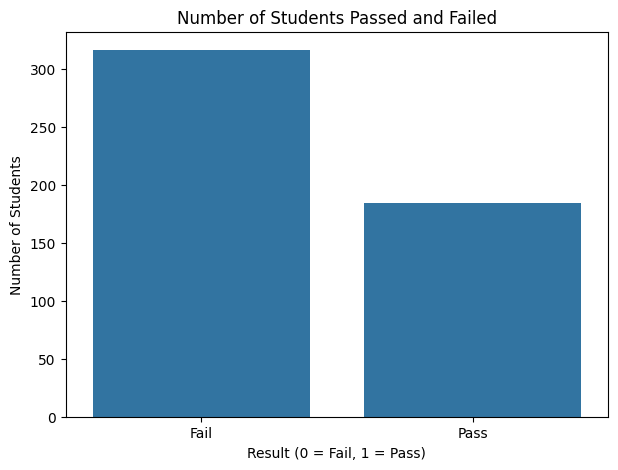

In [37]:
plt.figure(figsize=(7,5))

sns.countplot(x='Pass/Fail', data=df)

plt.title('Number of Students Passed and Failed')
plt.xlabel('Result (0 = Fail, 1 = Pass)')
plt.ylabel('Number of Students')

plt.xticks([0, 1], ['Fail', 'Pass'])

plt.show()

In [38]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

In [39]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

y_pred = knn.predict(X_test)

In [40]:
print("X_test:")
print(X_test)

print("\ny_test:")
print(y_test)

X_test:
[[-1.14636488  0.36414481]
 [ 0.47216686 -0.54494808]
 [-0.22868559  0.90636791]
 [-0.69181549 -0.18295006]
 [ 1.34361213  1.2000487 ]
 [-0.65446274  1.74281867]
 [ 0.0046641   0.93493745]
 [ 0.80691985 -1.47485509]
 [ 0.42409095 -1.20201068]
 [ 1.33341983 -1.28705117]
 [ 1.62952812  0.90256374]
 [-0.54409386 -0.88360607]
 [-1.38732836 -1.68169813]
 [-0.59153367  0.53171246]
 [ 0.87710102 -1.38999806]
 [ 0.28522455 -0.27442066]
 [ 1.66413224 -0.14271907]
 [ 1.47534478  0.51191639]
 [ 0.39543476 -1.51980047]
 [-1.29259013  0.14406369]
 [ 1.09041059 -1.65036786]
 [ 0.49899607  0.43567072]
 [ 0.04496351 -1.20833572]
 [ 0.03070655 -0.98688826]
 [ 1.16000862 -1.19774855]
 [-1.24264833 -1.11307225]
 [ 0.36694254  1.40717474]
 [-0.33023434  1.19407887]
 [ 1.30054946 -1.62720322]
 [ 0.71810266 -0.87523886]
 [-1.23779242 -1.44989493]
 [ 0.47797945 -1.15889105]
 [ 1.37753346  0.0789948 ]
 [ 0.8148964  -0.63390151]
 [-1.41308908  1.83899225]
 [ 1.05434415 -1.52806737]
 [ 0.07580058 -0.839

In [41]:
comparison = pd.DataFrame({
    'Actual (y_test)': y_test.values,
    'Predicted (y_pred)': y_pred
})

print(comparison)

    Actual (y_test)  Predicted (y_pred)
0                 0                   0
1                 1                   0
2                 0                   0
3                 0                   0
4                 1                   1
..              ...                 ...
95                0                   0
96                1                   1
97                1                   1
98                0                   0
99                1                   1

[100 rows x 2 columns]


In [42]:
accuracy = accuracy_score(y_test, y_pred)

print("KNN Model Accuracy:", accuracy * 100, "%")

KNN Model Accuracy: 97.0 %


In [43]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[62  1]
 [ 2 35]]


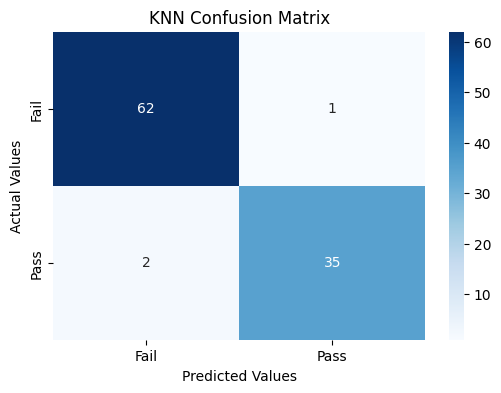

In [44]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Fail', 'Pass'],
    yticklabels=['Fail', 'Pass']
)

plt.xlabel('Predicted Values')
plt.ylabel('Actual Values')
plt.title('KNN Confusion Matrix')

plt.show()

In [45]:
# Extract true negatives, false positives, false negatives, and true positives from the confusion matrix
tn, fp, fn, tp = cm.ravel()

print("True Positives(TP):", tp)
print("True Negatives(TN):", tn)
print("False Positives(FP):", fp)
print("False Negatives(FN):", fn)

True Positives(TP): 35
True Negatives(TN): 62
False Positives(FP): 1
False Negatives(FN): 2


In [46]:
#ACCURACY
accuracy = (tp + tn) / (tp + tn + fp + fn)
print("Accuracy:", accuracy)

Accuracy: 0.97


In [47]:
#MISSCLASSIFICATION
MISSCLASSIFICATION = (fp + fn) / (tp + tn + fp + fn)
print("MISSCLASSIFICATION:", MISSCLASSIFICATION)

MISSCLASSIFICATION: 0.03


In [48]:
#TRUE POSITIVE RATE
TRUE_POSITIVE_RATE = tp / (tp + fn)
print("TRUE_POSITIVE_RATE:", TRUE_POSITIVE_RATE)

TRUE_POSITIVE_RATE: 0.9459459459459459


In [49]:
#TRUE NEGETIVE RATE
TRUE_NEGETIVE_RATE = tn / (tn + fp)
print("TRUE_NEGETIVE_RATE:", TRUE_NEGETIVE_RATE)


TRUE_NEGETIVE_RATE: 0.9841269841269841


In [50]:
#FALSE POSITIVE RATE
FALSE_POSITIVE_RATE = fp / (fp + tn)
print("FALSE_POSITIVE_RATE:", FALSE_POSITIVE_RATE)

FALSE_POSITIVE_RATE: 0.015873015873015872


In [51]:
#FALSE NEGETIVE RATE
FALSE_NEGETIVE_RATE = fn / (fn + tp)
print("FALSE_NEGETIVE_RATE:", FALSE_NEGETIVE_RATE)


FALSE_NEGETIVE_RATE: 0.05405405405405406


In [52]:
#PRECISION
PRECISION = tp / (tp + fp)
print("PRECISION:", PRECISION)

PRECISION: 0.9722222222222222


In [53]:
#F1 SCORE
F1_SCORE = 2 * (PRECISION * TRUE_POSITIVE_RATE) / (PRECISION + TRUE_POSITIVE_RATE)
print("F1_SCORE:", F1_SCORE)


F1_SCORE: 0.9589041095890412
